# One neuron, every model: maximum-response chords → `figure_example_model_neurons.pdf`

`figure_example_neurons.ipynb`'s ring style for **one neuron**, `UNIT` (unit 126, the most
relational example neuron), drawn once for each model in `MODELS`. Each ring shows the stimuli
that drive the neuron most, at each inter-object angle in `SEPARATIONS`: from that model's
cached all-trial fit to this neuron (`ring_lib.unit_fits`), the local maxima of its noise-free
predicted rate against the pair's midpoint direction (`example_neurons_lib.model_extreme_pairs`).
Every maximum found is drawn, up to `SEPARATIONS[sep]` per separation, even where a model's two
maxima differ in height.

The weighted-average model's rate depends on which two objects are on screen, so it is drawn for
one pair of object identities, `CONTRAST_PAIR`.

Every ring is turned by the unit's `rotation_deg` for display only, which puts its receptive field
at the top.


In [10]:
import numpy as np
import matplotlib.pyplot as plt

import common
common.set_style()
import contrast_lib
import example_neurons_lib as enl
import fit_lib
import models_lib
import ring_lib
import tuning_lib

OUTPUT = 'figure_example_model_neurons.pdf'
UNIT = ('Perle', '2022-06-11', 126, 169)     # subject, session, unit, rotation_deg (RF up)

# The models, left to right.
MODELS = (
    'weighted_average',
    'normalization',
    'inhibition',
    'basis_function',
    'future_field',
)

# The weighted-average model's pair of object identities.
CONTRAST_PAIR = ('c', 'b')

SEPARATIONS = {180: 1, 130: 2, 80: 2}        # inter-object angle -> how many chords

FIGSIZE = (5.7, 1.6)         # (width, height) in inches
RING_RADIUS = 0.43           # in axes fractions, as figure 2/4's rings
CHORD_LW = 2.0
DOT_SIZE = 14                # object positions at the chord ends
TITLE_PAD = -2.0          # gap between the top of each ring panel and its title, in points;
                          #   smaller = title closer to the ring (negative is fine: the ring
                          #   sits a little below the panel's top edge). matplotlib default: 6.
                          #   Titles are placed with y=1.0 so negative values take effect.
MAX_COLOR = tuning_lib.FIRING_RATE_CMAP(1.0)    # the hot end of the tuning plots' map


In [11]:
subject, session, unit_id, rotation_deg = UNIT
columns = []                 # (label, chords)

fits = ring_lib.unit_fits(subject, session, unit_id, fit_lib.FitConfig(), verbose=False)
models = models_lib.build_models(MODELS)
dctr = contrast_lib.relative_contrast(*CONTRAST_PAIR)
for m in MODELS:
    ch, rep = enl.drawn_model_chords(models[m], fits[m], SEPARATIONS,
                                     dctr=dctr if models[m].needs_contrast else None)
    label = models_lib.MODEL_LABELS_SHORT.get(m, m)
    print(f'── {label} ──', *rep, sep='\n  ')
    columns.append((label, ch))


── Weighted Avg. ──
  180° max #1: objects at  89.8° and 269.8°,  7.95 Hz
  130° max #1: objects at 100.2° and 230.2°,  8.37 Hz
  130° max #2: objects at 330.5° and 100.5°,  7.37 Hz
   80° max #1: objects at  97.0° and 177.0°,  8.73 Hz
   80° max #2: objects at  25.2° and 105.2°,  7.81 Hz
── Normalization ──
  180° max #1: objects at 281.2° and 101.2°,  6.52 Hz
  130° max #1: objects at 331.2° and 101.3°,  6.52 Hz
  130° max #2: objects at 101.3° and 231.3°,  6.52 Hz
   80° max #1: objects at 101.0° and 181.0°,  6.52 Hz
   80° max #2: objects at  21.5° and 101.5°,  6.52 Hz
── Inhibition ──
  180° max #1: objects at 275.0° and  95.0°,  8.32 Hz
  130° max #1: objects at  95.5° and 225.5°,  8.37 Hz
  130° max #2: objects at 315.5° and  85.5°,  7.07 Hz
   80° max #1: objects at  94.5° and 174.5°,  8.43 Hz
── Basis Func. ──
  180° max #1: objects at 281.8° and 101.8°,  8.67 Hz
  130° max #1: objects at 132.8° and 262.8°,  8.56 Hz
  130° max #2: objects at 300.8° and  70.8°,  8.56 Hz
   80° 

saved figure_example_model_neurons.pdf


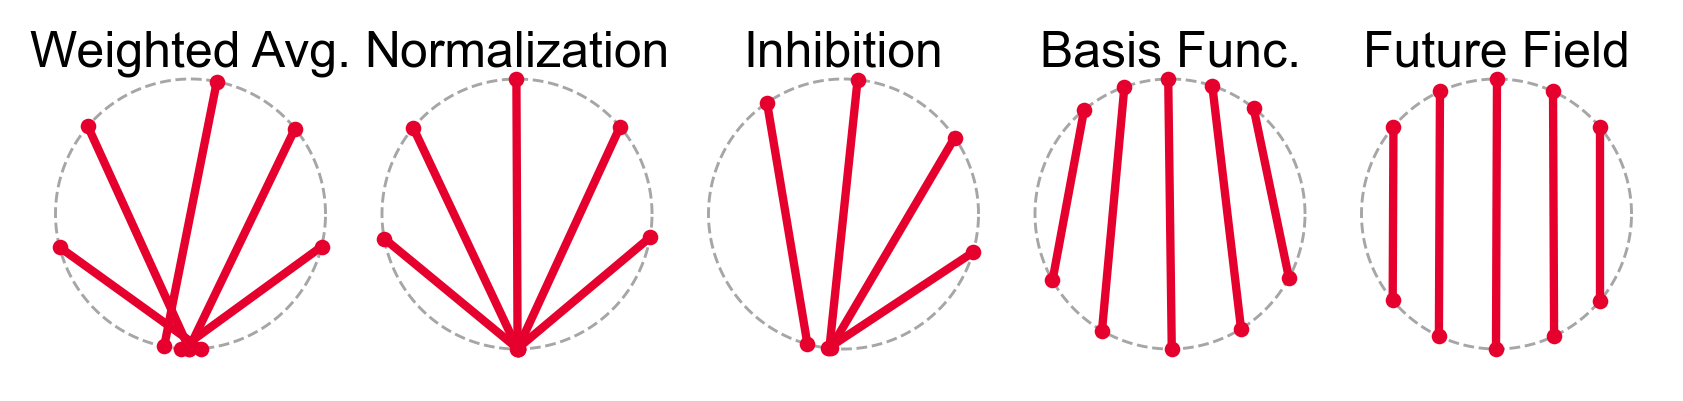

In [12]:
def draw_ring(ax, chords, rot_rad=0.0):
    tuning_lib.pl._prep_stim_ax(ax, RING_RADIUS)           # figure 2/4's ring axes
    ax.lines[-1].remove()                                  # no fixation cross: it is _prep_stim_ax's last line
    for a, c, *_ in chords:
        x = 0.5 + RING_RADIUS * np.cos(np.array([a, c]) + rot_rad)
        y = 0.5 + RING_RADIUS * np.sin(np.array([a, c]) + rot_rad)
        ax.plot(x, y, color=MAX_COLOR, lw=CHORD_LW, solid_capstyle='round', zorder=3)
        ax.scatter(x, y, s=DOT_SIZE, color=MAX_COLOR, zorder=4, linewidths=0)


fig, axes = plt.subplots(1, len(columns), figsize=FIGSIZE, squeeze=False)
for ax, (label, ch) in zip(axes[0], columns):
    draw_ring(ax, ch, np.radians(rotation_deg))
    ax.set_title(label, fontsize=12, pad=TITLE_PAD, y=1.0)
fig.tight_layout(w_pad=0.3)
common.save(fig, OUTPUT)
plt.show()